## Normality Tests

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# Generate one normal and one skewed dataset
np.random.seed(42)

# 100 exam scores: truly normal, mean=75, std=10
normal_scores = np.random.normal(loc=75, scale=10, size=100)

# 100 incomes: right-skewed lognormal data
skewed_income = np.random.lognormal(mean=10.0, sigma=0.5, size=100)

# Build DataFrame
df = pd.DataFrame({"normal_scores": normal_scores, "skewed_income": skewed_income})
print(df.describe())

       normal_scores  skewed_income
count     100.000000     100.000000
mean       73.961535   25092.641183
std         9.081684   13762.537671
min        48.802549    8438.960296
25%        68.990943   14723.115578
50%        73.730437   22973.204349
75%        79.059521   28830.367083
max        93.522782   85826.627684


In [3]:
# Test normality with Shapiro-Wilk and Kolmogorov-Smirnov
alpha = 0.05

for col in ["normal_scores", "skewed_income"]:
    data = df[col]

    # Shapiro-Wilk test: H0 = data is normal
    w, p_shapiro = stats.shapiro(data)

    # KS test vs standard normal: standardize first
    z = (data - data.mean()) / data.std(ddof=1)
    d, p_ks = stats.kstest(z, "norm")

    print(f"--- {col} ---")
    print(f"Shapiro W={w:.3f}, p={p_shapiro:.4f} -> {'NOT normal' if p_shapiro < alpha else 'normal (fail to reject H0)'}")
    print(f"KS D={d:.3f}, p={p_ks:.4f} -> {'NOT normal' if p_ks < alpha else 'normal (fail to reject H0)'}")

--- normal_scores ---
Shapiro W=0.990, p=0.6552 -> normal (fail to reject H0)
KS D=0.052, p=0.9386 -> normal (fail to reject H0)
--- skewed_income ---
Shapiro W=0.826, p=0.0000 -> NOT normal
KS D=0.155, p=0.0142 -> NOT normal


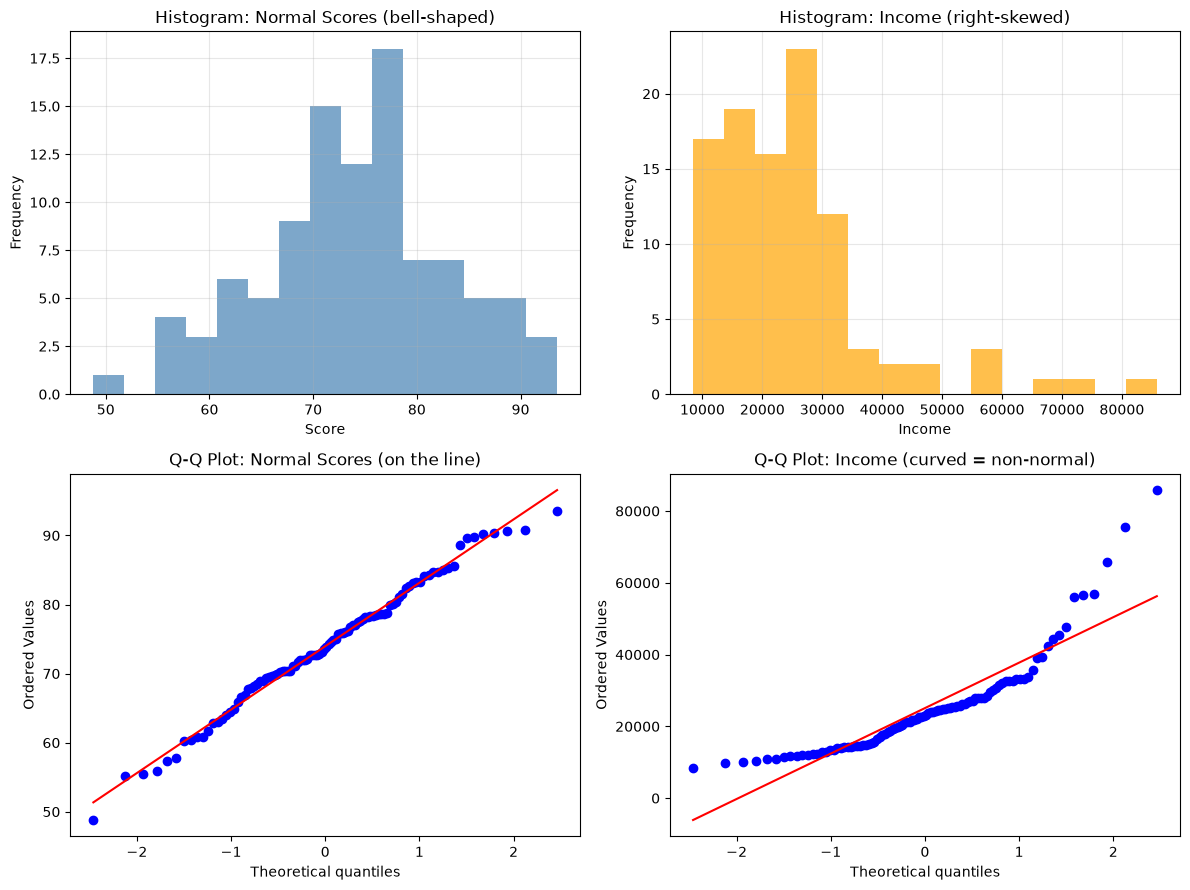

In [4]:
# Visualize with histograms and Q-Q plots
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Top-left: histogram of normal data
axes[0, 0].hist(df["normal_scores"], bins=15, color="steelblue", alpha=0.7)
axes[0, 0].set_title("Histogram: Normal Scores (bell-shaped)")
axes[0, 0].set_xlabel("Score")
axes[0, 0].set_ylabel("Frequency")
axes[0, 0].grid(alpha=0.3)

# Top-right: histogram of skewed data
axes[0, 1].hist(df["skewed_income"], bins=15, color="orange", alpha=0.7)
axes[0, 1].set_title("Histogram: Income (right-skewed)")
axes[0, 1].set_xlabel("Income")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].grid(alpha=0.3)

# Bottom-left: Q-Q plot of normal data, points should sit on the line
stats.probplot(df["normal_scores"], dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q-Q Plot: Normal Scores (on the line)")

# Bottom-right: Q-Q plot of skewed data, points curve away
stats.probplot(df["skewed_income"], dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot: Income (curved = non-normal)")

plt.tight_layout()
plt.show()

In [5]:
#  Experiment - big n sensitivity and log fix for skew
# Same skewed shape but n=5000: tiny deviation becomes significant
big_skewed = np.random.lognormal(mean=10.0, sigma=0.5, size=5000)
_, p_big = stats.shapiro(big_skewed[:5000] if len(big_skewed) <= 5000 else np.random.choice(big_skewed, 5000))
print(f"Skewed n=5000: Shapiro p={p_big:.5f} (almost always significant)")

# Log transform often fixes right skew
log_income = np.log(df["skewed_income"])
_, p_log = stats.shapiro(log_income)
print(f"After log transform: Shapiro p={p_log:.4f}")

# Question: Why does n=5000 reject normality even for tiny curves?
# Question: Does log make the income Q-Q plot straighter? Plot it yourself.

Skewed n=5000: Shapiro p=0.00000 (almost always significant)
After log transform: Shapiro p=0.0853
